### Apresentação

Este notebook foi criado para mostrar como você pode realizar análises rápidas e o acompanhamento de dados de produção utilizando gráficos interativos e dinâmicos da biblioteca Plotly, além de funções de manipulação e agregação do Pandas. Isso, combinado com uma visão espacial e temporal, otimiza a percepção do comportamento dos poços e ajuda a gerar insights valiosos para a gestão dos ativos.

### Descrição do Dado

Este conjunto de dados foi obtido gratuitamente no site da ANP (Agência Nacional do Petróleo, Gás Natural e Biocombustíveis) e engloba informações oficiais de poços no Brasil, com foco espacial e temporal nos dados do campo de Rio Urucu, localizado na Bacia de Solimões (Amazonas). 

Os dados estão divididos em duas tabelas complementares: a tabela de produção e a tabela cadastral de poços. A primeira consiste em uma base de dados dinâmicos com séries temporais mensais que detalham volumes e vazões diárias de óleo, gás natural, condensado, água e petróleo por poço. A segunda representa o cadastro estático e histórico dos poços, fornecendo informações cadastrais relevantes como a situação atual, bacia, estado, operador e coordenadas geográficas de base (latitude e longitude em graus decimais), essenciais para análises espaciais e cruzamentos estruturais.

In [1]:
import pandas as pd
import plotly.express as px
import plotly.io as pio 

caminho = "C:/Users/lucas.aguiar/Desktop/Pastas/B2S/5_plotly_dados_producao/"

In [2]:
# Importação dos dados de produção por poço
producao = pd.read_excel(caminho + "producao_poco_rio_urucu.xlsx", skipfooter=2)
print("Formato dos dados de produção:", producao.shape)

Formato dos dados de produção: (12767, 20)


In [3]:
# Prévia do dado de produção
print(producao.columns)
producao.head(5)

Index(['Período', 'Campo', 'Poço ANP', 'Bacia', 'Estado', 'Operadora atual',
       'Gás Natural (mil m3)', 'Gás Natural Associado (mil m3)',
       'Gás Natural Não Associado (mil m3)', 'Óleo (bbl)', 'Óleo (bbl/d)',
       'Condensado (bbl)', 'Condensado (bbl/d)', 'Gás Natural (mil m3/d)',
       'Gás Natural Associado (mil m3/d)',
       'Gás Natural Não Associado (mil m3/d)', 'Água (bbl)', 'Água (bbl/d)',
       'Petróleo (bbl)', 'Petróleo (bbl/d)'],
      dtype='str')


,Período,Campo,Poço ANP,Bacia,Estado,Operadora atual,Gás Natural (mil m3),Gás Natural Associado (mil m3),Gás Natural Não Associado (mil m3),Óleo (bbl),Óleo (bbl/d),Condensado (bbl),Condensado (bbl/d),Gás Natural (mil m3/d),Gás Natural Associado (mil m3/d),Gás Natural Não Associado (mil m3/d),Água (bbl),Água (bbl/d),Petróleo (bbl),Petróleo (bbl/d)
0,2025/01,RIO URUCU,3-BRSA-1164DP-AM,Solimões,Amazonas,Petrobras,2342.800,0.000,2342.805,0.000000,0.000000,1225.927998,39.546064,75.574194,0.000000,75.574355,0.383678,0.012377,1225.927998,39.546064
1,2025/01,RIO URUCU,3-BRSA-515-AM,Solimões,Amazonas,Petrobras,6117.340,6117.343,0.000,4514.064551,145.614986,0.000000,0.000000,197.333548,197.333645,0.000000,195.374078,6.302390,4514.064551,145.614986
2,2025/01,RIO URUCU,3-RUC-16D-AM,Solimões,Amazonas,Petrobras,5389.150,0.000,5389.154,0.000000,0.000000,2014.198436,64.974143,173.843548,0.000000,173.843677,0.000000,0.000000,2014.198436,64.974143
3,2025/01,RIO URUCU,3-RUC-8-AM,Solimões,Amazonas,Petrobras,7239.380,0.000,7239.377,0.000000,0.000000,3931.533798,126.823671,233.528387,0.000000,233.528290,35.128589,1.133180,3931.533798,126.823671
4,2025/01,RIO URUCU,3-SUC-3-AM,Solimões,Amazonas,Petrobras,347.162,347.162,0.000,4805.710461,155.022918,0.000000,0.000000,11.198774,11.198774,0.000000,28561.869965,921.350644,4805.710461,155.022918


In [4]:
# Criação de dados com produção acumulada de óleo por poço
producao_acum = producao.groupby(["Poço ANP"]).agg({"Óleo (bbl)":["sum"]})
producao_acum = producao_acum.reset_index()

producao_acum.head(10)

,Poço ANP,Óleo (bbl)
,,sum
0,1-RUC-1-AM,1.312018e+06
1,3-BRSA-1164DP-AM,0.000000e+00
2,3-BRSA-1171DP-AM,1.546128e+04
3,3-BRSA-515-AM,1.830027e+06
4,3-BRSA-670-AM,4.643702e+05
5,3-RUC-11D-AM,5.213850e+06
6,3-RUC-12-AM,1.533590e+06
7,3-RUC-13D-AM,4.270554e+06
8,3-RUC-14D-AM,1.361838e+05


In [5]:
# Renomear as colunas
producao_acum.columns = ["POCO","ÓLEO (bbl)"]

In [6]:
# Importação da tabela de poços ANP com dados estáticos
tabela_anp = pd.read_excel(caminho + "tabela-de-pocos.xlsx", decimal=",")
print("Formato dos dados estáticos de poços:", tabela_anp.shape)

Formato dos dados estáticos de poços: (30926, 60)


In [7]:
# Prévia da tabela de poços ANP
print(tabela_anp.columns)
tabela_anp.head(5)

Index(['POCO', 'CADASTRO', 'OPERADOR', 'POCO_OPERADOR', 'ESTADO', 'BACIA',
       'BLOCO', 'SIG_CAMPO', 'CAMPO', 'TERRA_MAR', 'POCO_POS_ANP', 'TIPO',
       'CATEGORIA', 'RECLASSIFICACAO', 'SITUACAO', 'INICIO', 'TERMINO',
       'CONCLUSAO', 'TITULARIDADE', 'LATITUDE_BASE_4C', 'LONGITUDE_BASE_4C',
       'LATITUDE_BASE_DD', 'LONGITUDE_BASE_DD', 'DATUM_HORIZONTAL',
       'TIPO_DE_COORDENADA_DE_BASE', 'DIRECAO', 'PROFUNDIDADE_VERTICAL_M',
       'PROFUNDIDADE_SONDADOR_M', 'PROFUNDIDADE_MEDIDA_M',
       'REFERENCIA_DE_PROFUNDIDADE', 'MESA_ROTATIVA', 'COTA_ALTIMETRICA_M',
       'LAMINA_D_AGUA_M', 'DATUM_VERTICAL', 'UNIDADE_ESTRATIGRAFICA',
       'GEOLOGIA_GRUPO_FINAL', 'GEOLOGIA_FORMACAO_FINAL',
       'GEOLOGIA_MEMBRO_FINAL', 'CDPE', 'AGP', 'PC', 'PAG',
       'PERFIS_CONVENCIONAIS', 'DURANTE_PERFURACAO', 'PERFIS_DIGITAIS',
       'PERFIS_PROCESSADOS', 'PERFIS_ESPECIAIS', 'AMOSTRA_LATERAL', 'SISMICA',
       'TABELA_TEMPO_PROFUNDIDADE', 'DADOS_DIRECIONAIS', 'TESTE_A_CABO',
       'TES

,POCO,CADASTRO,OPERADOR,POCO_OPERADOR,ESTADO,BACIA,BLOCO,SIG_CAMPO,CAMPO,TERRA_MAR,...,DADOS_DIRECIONAIS,TESTE_A_CABO,TESTE_DE_FORMACAO,CANHONEIO,TESTEMUNHO,GEOQUIMICA,SIG_SONDA,NOM_SONDA,ATINGIU_PRESAL,DHA_ATUALIZACAO
0,1-AA-1-RN,721000712200,NaN,1AA 0001 RN,RN,Potiguar,Brasil,NaN,NaN,T,...,NaN,NaN,NaN,NaN,NaN,Existe,CC-1,NaN,NaN,2025-02-23 05:00:59
1,1-ABV-1D-RN,721000514700,Potiguar E&P S.A.,1ABV 0001D RN,RN,Potiguar,BT-POT-9,PAT,PATATIVA,T,...,NaN,NaN,NaN,NaN,NaN,Existe,SC-110,SONDA CONVENCIONAL 110,NaN,2025-02-23 05:00:59
2,1-AB-1A-SE,901200015200,NaN,1AB 0001A SE,SE,Sergipe,Brasil,NaN,NaN,T,...,NaN,NaN,NaN,NaN,NaN,Existe,SC-61,SONDA CONVENCIONAL 61,NaN,2025-02-23 05:00:59
3,1-AB-1-BA,202200153900,NaN,1AB 0001 BA,BA,Tucano Central,Brasil,NaN,NaN,T,...,NaN,NaN,NaN,NaN,NaN,Existe,SC-53,SONDA CONVENCIONAL 53,NaN,2025-02-23 05:00:59
4,1-AB-1-PA,600300063100,NaN,1AB 0001 PA,PA,Amazonas,Brasil,NaN,NaN,T,...,NaN,NaN,NaN,NaN,NaN,Existe,SM-1,NaN,NaN,2025-02-23 05:00:59


In [8]:
# Associação de coordenadas aos poços
producao_acum = pd.merge(producao_acum,
                         tabela_anp[["POCO",
                                     'LATITUDE_BASE_DD',
                                     'LONGITUDE_BASE_DD']],
                         how="left",
                         on="POCO")

producao_acum.head(10)

,POCO,ÓLEO (bbl),LATITUDE_BASE_DD,LONGITUDE_BASE_DD
0,1-RUC-1-AM,1.312018e+06,-4.887199,-65.304466
1,3-BRSA-1164DP-AM,0.000000e+00,-4.892355,-65.335947
2,3-BRSA-1171DP-AM,1.546128e+04,-4.844494,-65.241667
3,3-BRSA-515-AM,1.830027e+06,-4.813321,-65.232983
4,3-BRSA-670-AM,4.643702e+05,-4.879881,-65.289785
5,3-RUC-11D-AM,5.213850e+06,-4.823027,-65.248178
6,3-RUC-12-AM,1.533590e+06,-4.823053,-65.248385
7,3-RUC-13D-AM,4.270554e+06,-4.892038,-65.318253
8,3-RUC-14D-AM,1.361838e+05,-4.904740,-65.327746
9,3-RUC-16D-AM,6.356353e+06,-4.866954,-65.300254


### Graficos interativos (dispersão)

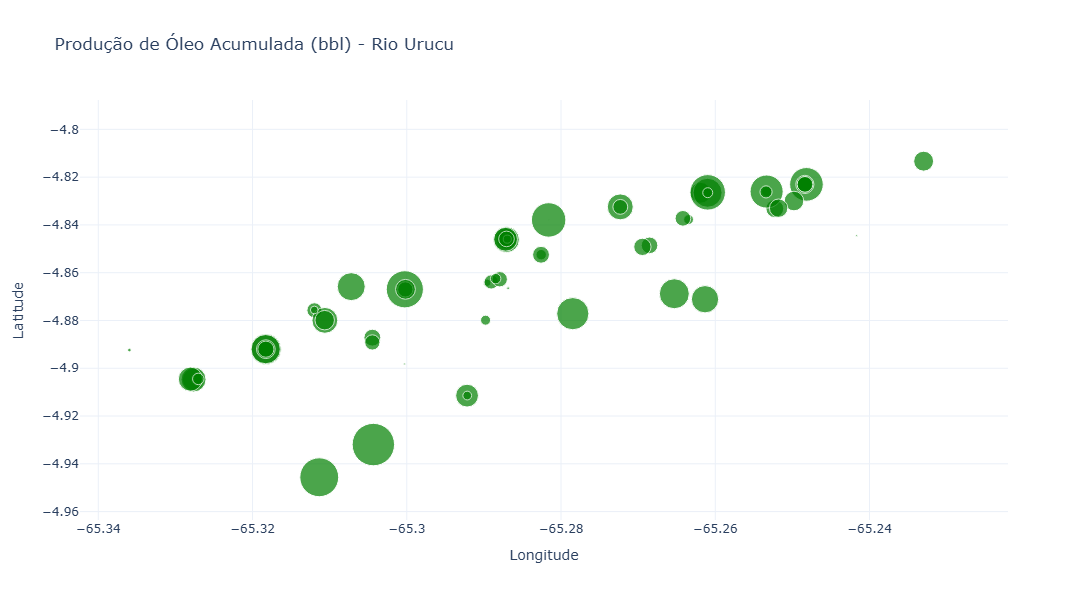

In [9]:
# Criação do gráfico de produção acumulada em visão espacial
fig = px.scatter(producao_acum,
                 x="LONGITUDE_BASE_DD",
                 y="LATITUDE_BASE_DD",
                 size="ÓLEO (bbl)",
                 hover_name="POCO",
                 size_max=30,
                 color_discrete_sequence=["green"],
                 title="Produção de Óleo Acumulada (bbl) - Rio Urucu",
                 template="plotly_white")

fig.update_layout(xaxis_title="Longitude",
                  yaxis_title="Latitude",
                  width=900, 
                  height=600)

### Observação

Ao passar o cursor por cima dos pontos, é possível visualizar as informações utilizadas de cada poço. Também é possível usar o cursor para aumentar o zoom do gráfico em pontos específicos.

In [10]:
# Seleção do poço
poco = producao.loc[producao["Poço ANP"] == "7-RUC-39HP-AM"]

In [11]:
# Tipos de dados
poco.dtypes

Período                                     str
Campo                                       str
Poço ANP                                    str
Bacia                                       str
Estado                                      str
Operadora atual                             str
Gás Natural (mil m3)                    float64
Gás Natural Associado (mil m3)          float64
Gás Natural Não Associado (mil m3)      float64
Óleo (bbl)                              float64
Óleo (bbl/d)                            float64
Condensado (bbl)                        float64
Condensado (bbl/d)                      float64
Gás Natural (mil m3/d)                  float64
Gás Natural Associado (mil m3/d)        float64
Gás Natural Não Associado (mil m3/d)    float64
Água (bbl)                              float64
Água (bbl/d)                            float64
Petróleo (bbl)                          float64
Petróleo (bbl/d)                        float64
dtype: object

In [12]:
# Conversão de formato de data
poco["Período"] = pd.to_datetime(poco["Período"])

poco.dtypes

C:\Users\LAguiar6\AppData\Local\Temp\ipykernel_35884\1482048790.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  poco["Período"] = pd.to_datetime(poco["Período"])


Período                                 datetime64[us]
Campo                                              str
Poço ANP                                           str
Bacia                                              str
Estado                                             str
Operadora atual                                    str
Gás Natural (mil m3)                           float64
Gás Natural Associado (mil m3)                 float64
Gás Natural Não Associado (mil m3)             float64
Óleo (bbl)                                     float64
Óleo (bbl/d)                                   float64
Condensado (bbl)                               float64
Condensado (bbl/d)                             float64
Gás Natural (mil m3/d)                         float64
Gás Natural Associado (mil m3/d)               float64
Gás Natural Não Associado (mil m3/d)           float64
Água (bbl)                                     float64
Água (bbl/d)                                   float64
Petróleo (

### Graficos interativos (linha)

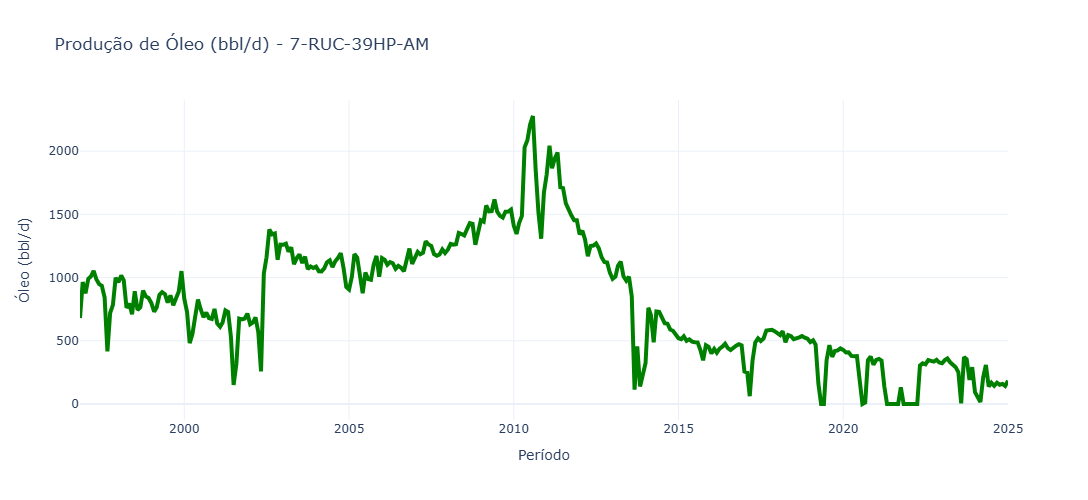

In [13]:
# Gráfico de linha
fig = px.line(poco,
              x="Período",
              y="Óleo (bbl/d)",
              title="Produção de Óleo (bbl/d) - 7-RUC-39HP-AM",
              template="plotly_white")

fig.update_traces(line_color="green",
                  line_width=4)

fig.update_layout(width=900, 
                  height=500)